# UMAP del conjunto unificado

En este notebook se analiza el modelo entrenado con mejores resultados, model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.pth.
Para este análisis se utilizará una técnica de reducción de dimensionalidad no lineal denominada UMAP (Uniform Manifold Approximation and Projection).




## Configuración

In [1]:
# Importaciones

from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models
from torchvision.datasets.folder import IMG_EXTENSIONS, default_loader
from umap import UMAP

from vasijas.config import load_config
from vasijas.paths import ProjectPaths, ruta_relativa
from vasijas.metadata import cargar_metadata
from vasijas.evaluacion import validar_identificadores_metadata
from vasijas.entrenamiento_cnn import (
    ConfiguracionTransformacionesImagen,
    crear_transformaciones_imagen,
    seleccionar_dispositivo_procesamiento,
)
from vasijas.umap_evaluacion import (
    ConfiguracionUmap,
    graficar_umap_test,
    guardar_resultado_umap,
)

In [2]:
# Configuración
CONFIG = load_config()
PATHS = ProjectPaths.from_root(CONFIG.project_root)
DATA_DIR = PATHS.DATA_UNIFICADO
MODEL_PATH = (
    PATHS.OUTPUT_MODELS / "model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.pth"
)
OUTPUT_DIR = PATHS.OUTPUT_UMAP
CSV_PATH = OUTPUT_DIR / f"umap_unificado_{MODEL_PATH.stem}.csv"
FIGURE_PATH = OUTPUT_DIR / f"umap_unificado_{MODEL_PATH.stem}.png"
CLASES_UTILIZADAS = (1, 2, 3, 5, 6, 7, 8, 9, 10, 11)
BATCH_SIZE = 16
TAMANO_IMAGEN = 224
UMAP_CONFIG = ConfiguracionUmap(
    n_neighbors=30,
    min_dist=0.1,
    metric="cosine",
    random_state=42,
)
DEVICE = seleccionar_dispositivo_procesamiento()

print(f"metadata: {ruta_relativa(DATA_DIR / 'metadata.csv')}")
print(f"modelo: {MODEL_PATH.name}")
print(f"dispositivo: {DEVICE}")
print(f"batch_size: {BATCH_SIZE}")
print(f"tamano_imagen: {TAMANO_IMAGEN}")
for nombre, valor in asdict(UMAP_CONFIG).items():
    print(f"{nombre}: {valor}")

metadata: data\11.unificado\metadata.csv
modelo: model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.pth
dispositivo: cpu
batch_size: 16
tamano_imagen: 224
n_neighbors: 30
min_dist: 0.1
metric: cosine
random_state: 42


## Preparación de los datos

Se utilizan únicamente las clases 1, 2, 3, 5, 6, 7, 8, 9, 10 y 11. Se filtra la columna `Clase Ana` antes de buscar las imágenes y se admiten sólo las carpetas correspondientes (`clase01` a `clase11`, excluida `clase04`). Quedan fuera la clase 4, `sin_clase` y los valores de clase faltantes o no válidos.

Se busca exactamente un archivo por identificador seleccionado dentro del directorio unificado. Los identificadores duplicados, las imágenes faltantes o las rutas ambiguas de las clases seleccionadas detienen el proceso. Las imágenes ajenas al CSV no se incorporan.

Se conserva el orden y todas las columnas de las filas seleccionadas del CSV, incluidos los valores faltantes de las demás columnas. Se agregan `ruta_relativa` y `clase_carpeta` a partir del archivo encontrado. No se crea un split. El preprocesamiento es el del notebook 16: 224 × 224 y normalización ImageNet, sin aumentación.

In [3]:
metadata_unificado = cargar_metadata(DATA_DIR)
metadata_unificado = (
    metadata_unificado.loc[
        pd.to_numeric(metadata_unificado["Clase Ana"], errors="coerce").isin(
            CLASES_UTILIZADAS
        )
    ]
    .copy()
    .reset_index(drop=True)
)
validar_identificadores_metadata(metadata_unificado)
if metadata_unificado.empty:
    raise ValueError("No hay imágenes de las clases permitidas en la metadata.")

identificadores = metadata_unificado["Identificador"].astype(str)
buscados = set(identificadores)
carpetas_permitidas = {f"clase{clase:02d}" for clase in CLASES_UTILIZADAS}
rutas_por_id = {}
for ruta in sorted(DATA_DIR.rglob("*")):
    if (
        ruta.is_file()
        and ruta.relative_to(DATA_DIR).parts[0] in carpetas_permitidas
        and ruta.suffix.lower() in IMG_EXTENSIONS
        and ruta.stem in buscados
    ):
        if ruta.stem in rutas_por_id:
            raise ValueError(f"Hay varias imágenes para {ruta.stem!r}.")
        rutas_por_id[ruta.stem] = ruta

faltantes = buscados - set(rutas_por_id)
if faltantes:
    raise FileNotFoundError(
        f"Faltan {len(faltantes)} imágenes: {sorted(faltantes)[:10]}"
    )

metadata_imagenes = metadata_unificado.copy().reset_index(drop=True)
metadata_imagenes["ruta_relativa"] = [
    rutas_por_id[identificador].relative_to(DATA_DIR).as_posix()
    for identificador in identificadores
]
metadata_imagenes["clase_carpeta"] = metadata_imagenes["ruta_relativa"].map(
    lambda ruta: Path(ruta).parts[0]
)
if not metadata_imagenes["ruta_relativa"].is_unique:
    raise ValueError("Las rutas de las imágenes deben ser únicas.")

display(metadata_imagenes.groupby("clase_carpeta").size().rename("imagenes").to_frame())
display(metadata_imagenes.head(5))
print(f"Total de imágenes referenciadas y encontradas: {len(metadata_imagenes)}")
print(f"Valores faltantes en Clase Ana: {metadata_imagenes['Clase Ana'].isna().sum()}")

,imagenes
clase_carpeta,
clase01,494
clase02,874
clase03,1349
clase05,1064
clase06,969
clase07,912
clase08,5320
clase09,380
clase10,6745


,Identificador,Tiene asa,Tendencia Formal,Borde,Cuello,Cuerpo,Base,Clase Ana,Diametro Borde,Diametro Base,Altura Total,Cronologia,Ubicacion,id_perfil_completo,borde_origen,porcentaje_avance,ruta_relativa,clase_carpeta
0,al_03a,No,II,1,B,2,2,11.0,182,54,53,ibero,Almedinilla,al_03a,completo,100.0,clase11/al_03a.png,clase11
1,al_03b,No,II,1,B,2,2,11.0,178,57,46,ibero,Almedinilla,al_03b,completo,100.0,clase11/al_03b.png,clase11
2,al_03c,No,II,1,B,2,2,11.0,185,56,49,ibero,Almedinilla,al_03c,completo,100.0,clase11/al_03c.png,clase11
3,al_03d,No,II,1,B,2,2,11.0,160,41,45,ibero,Almedinilla,al_03d,completo,100.0,clase11/al_03d.png,clase11
4,al_03e,No,II,1,B,2,2,11.0,164,54,44,ibero,Almedinilla,al_03e,completo,100.0,clase11/al_03e.png,clase11


Total de imágenes referenciadas y encontradas: 20349
Valores faltantes en Clase Ana: 0


In [4]:
class DatasetUnificadoConRuta(Dataset):
    """Carga RGB y devuelve la ruta para verificar la identidad de cada vector."""

    def __init__(self, metadata, data_dir, transformacion):
        self.rutas = metadata["ruta_relativa"].tolist()
        self.data_dir = data_dir
        self.transformacion = transformacion

    def __len__(self):
        return len(self.rutas)

    def __getitem__(self, indice):
        ruta = self.rutas[indice]
        imagen = default_loader(str(self.data_dir / ruta))
        return self.transformacion(imagen), ruta


transformacion_evaluacion = crear_transformaciones_imagen(
    ConfiguracionTransformacionesImagen(tamano_imagen=TAMANO_IMAGEN)
)[2]
dataset_unificado = DatasetUnificadoConRuta(
    metadata_imagenes, DATA_DIR, transformacion_evaluacion
)
loader_unificado = DataLoader(
    dataset_unificado,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)
print(f"Imágenes: {len(dataset_unificado)} · Lotes: {len(loader_unificado)}")

Imágenes: 20349 · Lotes: 1272


## Extracción de características

Se reconstruye la misma ResNet18 a partir de sus pesos locales, sin descargar pesos. La cantidad de salidas del clasificador se lee del archivo del modelo; no depende de las carpetas del unificado, que también contiene imágenes sin clase. Se extraen únicamente las características anteriores al clasificador, en modo evaluación y sin gradientes.

Se verifica un vector por imagen, incluido el último lote incompleto. Los vectores quedan en memoria para repetir UMAP con otros parámetros.

In [5]:
state_dict = torch.load(MODEL_PATH, map_location="cpu", weights_only=True)
modelo = models.resnet18(weights=None)
modelo.fc = nn.Linear(modelo.fc.in_features, state_dict["fc.weight"].shape[0])
modelo.load_state_dict(state_dict, strict=True)
del state_dict
modelo = modelo.to(DEVICE).eval()
extractor = nn.Sequential(*list(modelo.children())[:-1], nn.Flatten(1)).eval()

bloques = []
rutas_extraidas = []
with torch.inference_mode():
    for numero_lote, (imagenes, rutas) in enumerate(loader_unificado, start=1):
        vectores = extractor(imagenes.to(DEVICE))
        bloques.append(vectores.cpu().numpy())
        rutas_extraidas.extend(rutas)
        if numero_lote % 100 == 0 or numero_lote == len(loader_unificado):
            print(f"Características: {len(rutas_extraidas)}/{len(dataset_unificado)}")

if rutas_extraidas != metadata_imagenes["ruta_relativa"].tolist():
    raise ValueError("Los vectores no corresponden al orden completo de la metadata.")
caracteristicas_unificado = np.concatenate(bloques, axis=0)
del bloques
if caracteristicas_unificado.shape != (len(metadata_unificado), 512):
    raise ValueError("Debe existir un vector de 512 características por imagen.")
if not np.isfinite(caracteristicas_unificado).all():
    raise ValueError("Las características contienen valores no finitos.")
metadata_caracteristicas = metadata_imagenes.copy()
print(f"Matriz de características verificada: {caracteristicas_unificado.shape}")

Características: 1600/20349
Características: 3200/20349
Características: 4800/20349
Características: 6400/20349
Características: 8000/20349
Características: 9600/20349
Características: 11200/20349
Características: 12800/20349
Características: 14400/20349
Características: 16000/20349
Características: 17600/20349
Características: 19200/20349
Características: 20349/20349
Matriz de características verificada: (20349, 512)


## Proyección y visualización

Se ajusta UMAP sobre los vectores de las clases permitidas, con distancia coseno, semilla fija y un solo trabajo para reproducir el ajuste en el mismo entorno. Los metadatos, los identificadores y las clases no intervienen en el ajuste. Se representan únicamente las imágenes de las clases 1, 2, 3, 5, 6, 7, 8, 9, 10 y 11; la clase 4 y `sin_clase` no participan en el ajuste ni en el gráfico.

A diferencia de la función de proyección del notebook 16, que exige `split == "test"`, este ajuste trabaja directamente sobre el conjunto unificado.

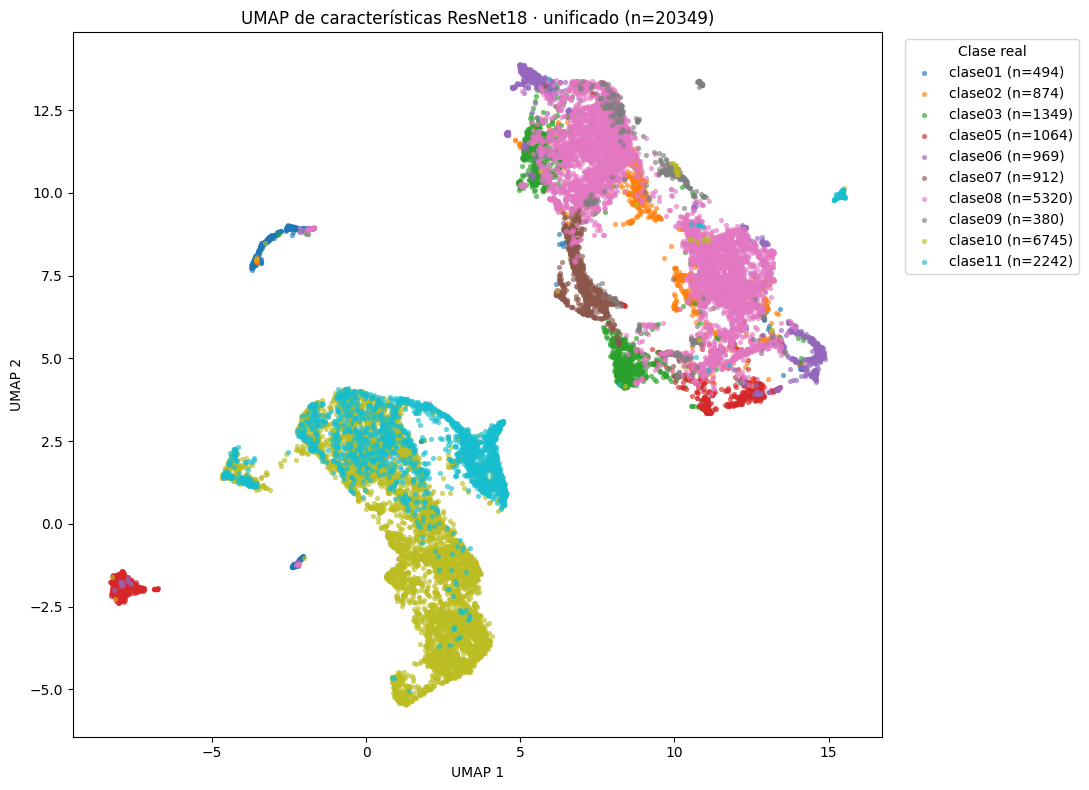

In [6]:
if not 2 <= UMAP_CONFIG.n_neighbors < len(caracteristicas_unificado):
    raise ValueError(
        "n_neighbors debe ser al menos 2 y menor que el número de imágenes."
    )
if not 0 <= UMAP_CONFIG.min_dist <= 1:
    raise ValueError("min_dist debe estar entre cero y uno.")

coordenadas = UMAP(
    n_components=2,
    **asdict(UMAP_CONFIG),
    n_jobs=1,
    init="random",
).fit_transform(caracteristicas_unificado)
if (
    coordenadas.shape != (len(metadata_unificado), 2)
    or not np.isfinite(coordenadas).all()
):
    raise ValueError("UMAP debe producir dos coordenadas finitas por imagen.")

tabla_umap = metadata_caracteristicas.copy()
tabla_umap[["UMAP_1", "UMAP_2"]] = coordenadas
# La función de dibujo se reutiliza; su título se adapta al conjunto completo.
figura_umap = graficar_umap_test(tabla_umap)
figura_umap.axes[0].set_title(
    f"UMAP de características ResNet18 · unificado (n={len(tabla_umap)})"
)
display(figura_umap)
plt.close(figura_umap)

## Exportación

El CSV conserva únicamente las filas de las clases permitidas, con todas sus columnas originales, sus valores faltantes y su orden; agrega las rutas, las carpetas y las coordenadas `UMAP_1` y `UMAP_2`. El PNG guarda la misma figura mostrada. Ambos archivos llevan el prefijo `umap_unificado_` en `../../output/umap`.

In [7]:
pd.testing.assert_frame_equal(
    tabla_umap[list(metadata_unificado.columns)],
    metadata_unificado.reset_index(drop=True),
)
rutas_guardadas = guardar_resultado_umap(
    tabla=tabla_umap,
    figura=figura_umap,
    ruta_csv=CSV_PATH,
    ruta_figura=FIGURE_PATH,
)
display(
    tabla_umap[
        ["Identificador", "ruta_relativa", "clase_carpeta", "UMAP_1", "UMAP_2"]
    ].head(10)
)
for ruta in rutas_guardadas:
    print(f"Archivo generado: {ruta_relativa(ruta)}")

,Identificador,ruta_relativa,clase_carpeta,UMAP_1,UMAP_2
0,al_03a,clase11/al_03a.png,clase11,3.718007,1.155122
1,al_03b,clase11/al_03b.png,clase11,3.608565,1.641703
2,al_03c,clase11/al_03c.png,clase11,3.150322,2.293321
3,al_03d,clase11/al_03d.png,clase11,3.226524,-1.466790
4,al_03e,clase11/al_03e.png,clase11,3.763974,1.237722
5,al_03f,clase11/al_03f.png,clase11,3.069016,2.622028
6,al_03g,clase11/al_03g.png,clase11,3.403349,2.006866
7,al_03h,clase11/al_03h.png,clase11,3.285997,2.237069
8,al_03i,clase11/al_03i.png,clase11,3.566760,1.164678
9,al_03j,clase11/al_03j.png,clase11,3.545136,1.473872


Archivo generado: output\umap\umap_unificado_model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.csv
Archivo generado: output\umap\umap_unificado_model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.png
